In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import rawpy

from src.demosaic import demosaic
from src.gamma import gamma_correction
from src.white_balance import gray_world
from src.hdr import get_hdr_raw
from src.icam06 import icam06_hdr
from src.process import process_raw

## 1 Investigate Bayer Patterns

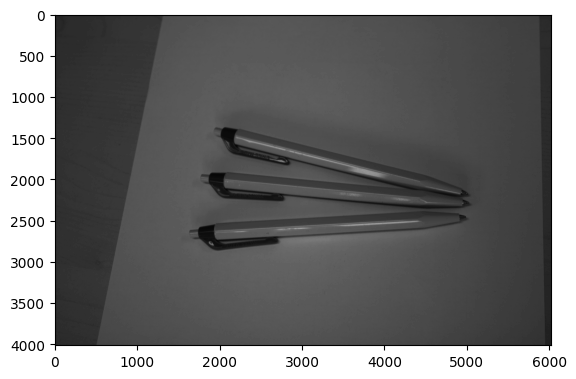

In [2]:
bayer = np.load("./exercise_2_data/01/IMG_9939.npy")

plt.imshow(bayer, cmap="gray") 
plt.show()

Print the average bright values:

In [3]:
print(f"(even, even): {bayer[ ::2,  ::2].mean()}")
print(f"(even, odd):  {bayer[ ::2, 1::2].mean()}")
print(f"(odd, even):  {bayer[1::2,  ::2].mean()}")
print(f"(odd, odd):   {bayer[1::2, 1::2].mean()}")

(even, even): 4488.386710963455
(even, odd):  3358.001626533048
(odd, even):  3296.3635245080754
(odd, odd):   4484.46299016565


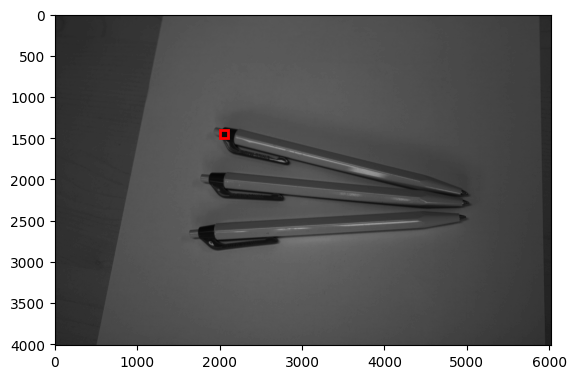

In [4]:
plt.imshow(bayer, cmap="gray") 
rect = patches.Rectangle((2000, 1400), 100, 100, linewidth=2, edgecolor='red', facecolor='none')
plt.gca().add_patch(rect)
plt.show()

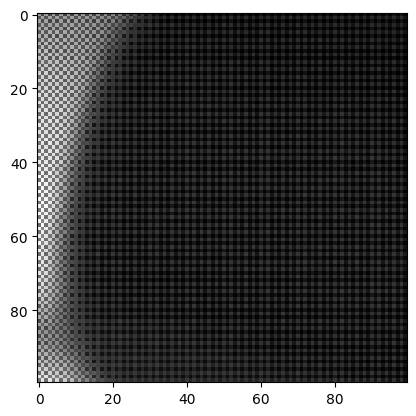

In [5]:
plt.imshow(bayer[1400:1500, 2000:2100], cmap="gray") 
plt.show()

In [6]:
print(bayer[1400:1500, 2000:2100][::2,::2].mean())
print(bayer[1400:1500, 2000:2100][::2,1::2].mean())
print(bayer[1400:1500, 2000:2100][1::2,::2].mean())
print(bayer[1400:1500, 2000:2100][1::2,1::2].mean())

2597.0184
2269.7072
2725.2816
2577.7468


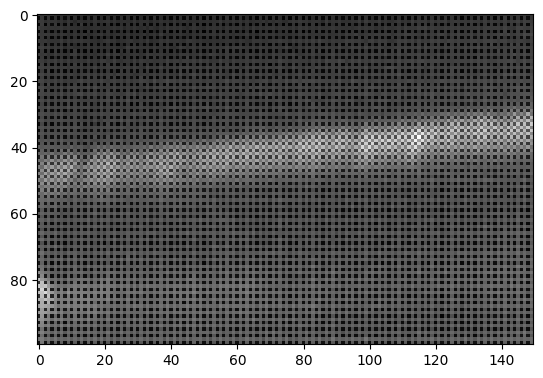

In [7]:
plt.imshow(bayer[2600:2700, 1750:1900], cmap="gray") 
plt.show()

In [8]:
print(bayer[2600:2700, 1750:1900][::2,::2].mean())
print(bayer[2600:2700, 1750:1900][::2,1::2].mean())
print(bayer[2600:2700, 1750:1900][1::2,::2].mean())
print(bayer[2600:2700, 1750:1900][1::2,1::2].mean())

2502.6042666666667
2517.7194666666664
2182.2002666666667
2502.8746666666666


## 2 Implement a Demosaicing Algorithm

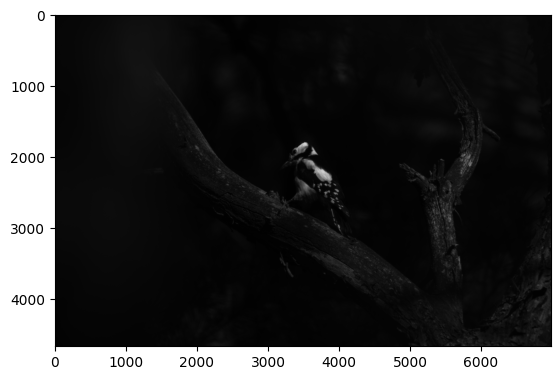

In [9]:
raw = rawpy.imread("./exercise_2_data/02/IMG_4782.CR3")
bayer = raw.raw_image_visible
plt.imshow(bayer, 'gray')

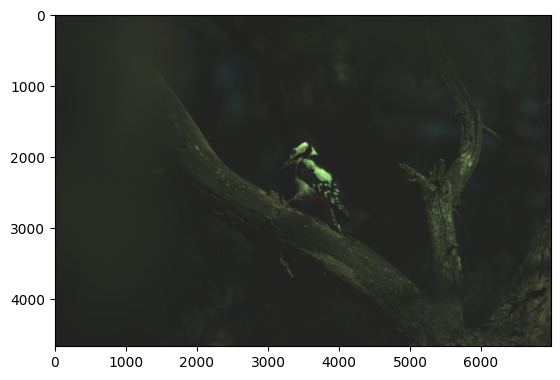

In [10]:
X = raw.raw_image_visible
pattern = raw.raw_pattern
rgb = demosaic(X, pattern)
plt.imshow(rgb/16383)

## 3 Improve the Luminosity

try with $\gamma = 3$

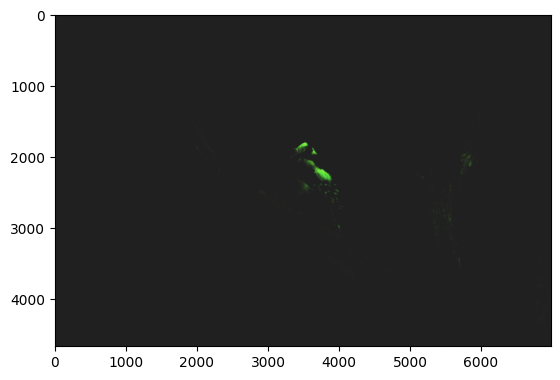

In [11]:
rgb_gamma = gamma_correction(rgb, gamma=3, method='power')
plt.imshow(rgb_gamma/16383)

try with $\gamma = 0.3$

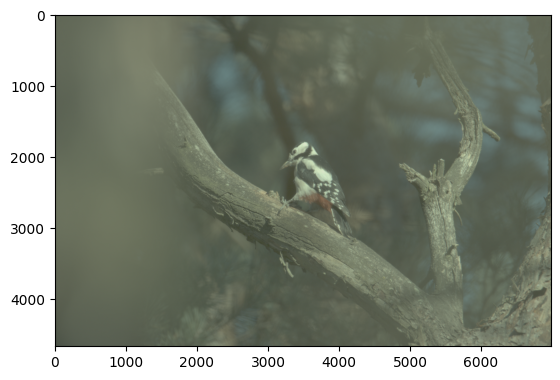

In [12]:
rgb_gamma = gamma_correction(rgb, gamma=0.3, method='power')
plt.imshow(rgb_gamma/16383)

try with log

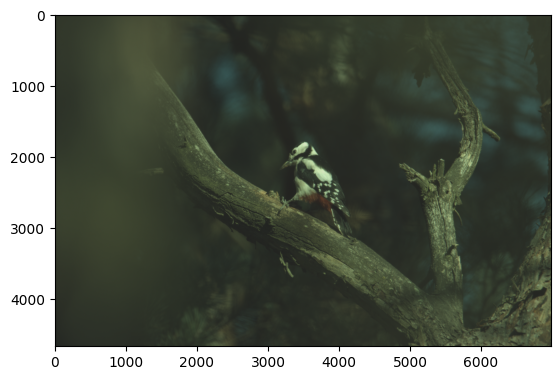

In [13]:
rgb_log = gamma_correction(rgb, method='log')
plt.imshow(rgb_log/16383)

## 4 White Balance

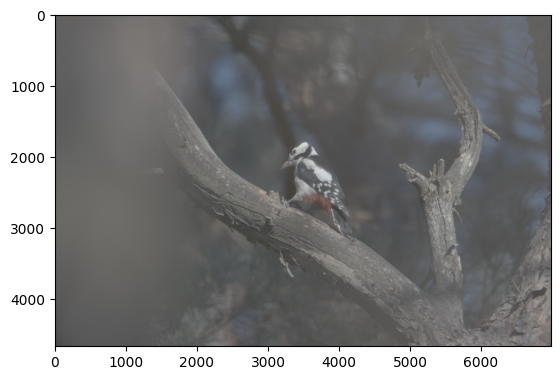

In [14]:
rgb_wb = gray_world(rgb_gamma)
plt.imshow(rgb_wb/16383)

## 5 Show that Sensor Data is Linear

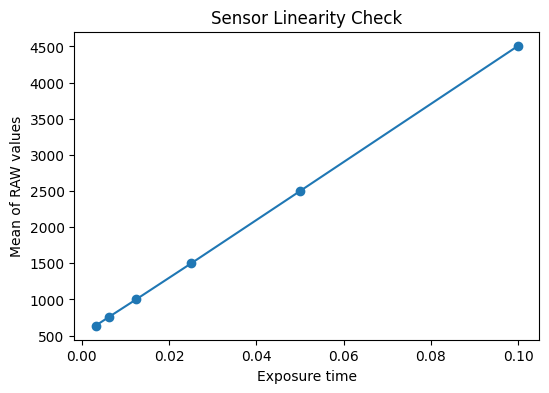

In [15]:
exposures = np.array([1/10, 1/20, 1/40, 1/80, 1/160, 1/320])
means = []

for n in range(3044, 3050):
    raw = rawpy.imread(f"./exercise_2_data/05/IMG_{n}.CR3")
    img = raw.raw_image_visible
    means.append(img.mean())

means = np.array(means)

plt.figure(figsize=(6,4))
plt.plot(exposures, means, '-o')
plt.xlabel("Exposure time")
plt.ylabel("Mean of RAW values")
plt.title("Sensor Linearity Check")
plt.show()

## 6 Initial HDR Implementation

In [16]:
files = [rawpy.imread(f"./exercise_2_data/06/{i:02d}.CR3").raw_image_visible.astype(np.float32) for i in range(11)]
pattern = rawpy.imread(f"./exercise_2_data/06/00.CR3").raw_pattern
hdr_raw = get_hdr_raw(files)

In [17]:
rgb = demosaic(hdr_raw, pattern)
rgb_wb = gray_world(rgb)

In [18]:
rgb_log  = np.log(1 + rgb_wb) 
a = np.percentile(rgb_log, 0.01)
b = np.percentile(rgb_log, 99.99)
rgb_norm = (rgb_log - a) / (b - a)
rgb_norm = np.clip(rgb_norm, 0, 1)
rgb_8bit = (rgb_norm * 255).astype(np.uint8)

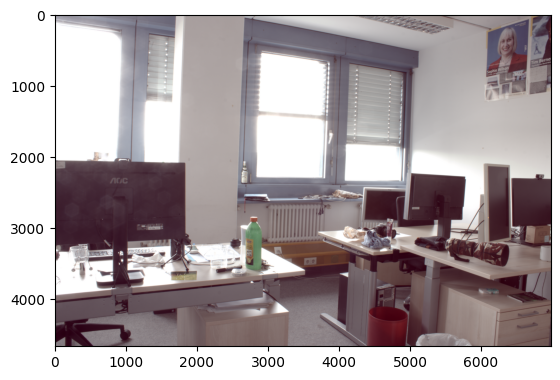

In [19]:
plt.imshow(rgb_8bit)

## 7 iCAM06

In [20]:
rgb_icam = icam06_hdr(rgb_wb)

In [21]:
rgb_8bit = (rgb_icam * 255).astype(np.uint8)

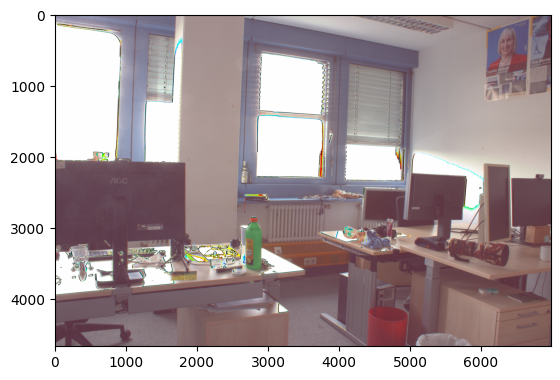

In [22]:
plt.imshow(rgb_8bit)

## 8 Win

In [23]:
input_path = "./exercise_2_data/02/IMG_4782.CR3"
output_path = "./results/IMG_4782.JPG"
process_raw(input_path, output_path)